In [109]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch
import cvxpy as cp
import matplotlib.pyplot as plt

# Find the awdro project directory.
current = Path.cwd().resolve()

root = next(
    (
        folder
        for folder in (current, *current.parents)
        if (folder / "hedging").is_dir()
        and (folder / "path simulation").is_dir()
        and (folder / "inner maximization").is_dir()
        and (folder / "outer minimization").is_dir()
    ),
    None,
)

if root is None:
    raise FileNotFoundError(
        f"Could not locate awdro from {current}. "
        "Save and open this notebook inside the awdro project."
    )

# Support your current folder structure, including folders with spaces.
for folder in [
    root,
    root / "hedging",
    root / "path simulation",
    root / "inner maximization",
    root / "outer minimization",
]:
    folder_string = str(folder)

    if folder_string not in sys.path:
        sys.path.insert(0, folder_string)

# Your project classes.
from Heston import Heston
from SuperhedgingProblem import SuperhedgingProblem
from NonrectangularSolver import NonrectangularSolver
from RectangularSolver import RectangularSolver
from RelaxedSuperhedgingSolver import RelaxedSuperhedgingSolver
from hedging.strategies import ConstantHedge

# Check that the saved outer solver contains both optimization methods.
for method_name in [
    "solve_constant_hedge_nonrectangular",
    "solve_constant_hedge_rectangular",
]:
    if not hasattr(RelaxedSuperhedgingSolver, method_name):
        raise AttributeError(
            f"RelaxedSuperhedgingSolver is missing {method_name}. "
            "Check that the method is inside the class, save the file, "
            "and restart the notebook kernel."
        )

if "CLARABEL" not in cp.installed_solvers():
    raise RuntimeError("Clarabel is required by your CVXPY methods.")

print("Project root:", root)
print("Imports and solver checks passed.")

Project root: /Users/jacve/Git/awdro
Imports and solver checks passed.


In [110]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

horizons = [0.25, 0.5, 1.0, 2.0]  # Years
budgets = [0.0, 0.5, 1.0, 2.0]
seeds = [123, 60, 44]

n_steps = 2
reference_branches = 2

strike = 150
penalty = 100

capital_bounds = (0.0, 1000.0)
holding_bounds = (-5.0, 5.0)

model = Heston(
    s0=100.0,
    v0=0.04,
    mu=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_vol=0.3,
    rho=-0.7,
)


def call_payoff(paths):
    return torch.clamp(paths[:, -1, 0] - strike, min=0.0)


def put_payoff(paths):
    return torch.clamp(strike - paths[:, -1, 0], min=0.0)

def digital_call(paths, cash=1.0):
    """Pay cash if S_T > strike; otherwise pay zero."""
    s_terminal = paths[:, -1, 0]
    return cash * (s_terminal > strike)



payoffs = {
    "European call": call_payoff,
    "Digital call": digital_call,
}

output_dir = root / "results" / "constant_hedge_sweep"
output_dir.mkdir(parents=True, exist_ok=True)

print(
    "Number of paired comparisons:",
    len(horizons) * len(budgets) * len(seeds) * len(payoffs),
)

Number of paired comparisons: 96


In [111]:
records = []

total = len(horizons) * len(budgets) * len(seeds) * len(payoffs)
completed = 0

for horizon in horizons:
    trading_times = np.linspace(0.0, horizon, n_steps + 1)

    for seed in seeds:
        settings = {
            "reference_branches": reference_branches,
            "seed": seed,
        }

        for budget in budgets:
            rectangular = RectangularSolver(
                reference_model=model,
                trading_times=trading_times,
                budget=budget,
                discretization=settings,
            )

            nonrectangular = NonrectangularSolver(
                reference_model=model,
                trading_times=trading_times,
                budget=budget,
                discretization=settings,
            )

            # Verify identical reference trees.
            np.testing.assert_array_equal(
                np.asarray([
                    node["state"]
                    for node in rectangular.reference_nodes
                ]),
                np.asarray([
                    node["state"]
                    for node in nonrectangular.reference_nodes
                ]),
            )

            for t in range(len(trading_times)):
                np.testing.assert_array_equal(
                    rectangular.adversarial_candidates[t],
                    nonrectangular.adversarial_candidates[t],
                )

            for payoff_name, payoff_fn in payoffs.items():
                problem = SuperhedgingProblem(
                    payoff=payoff_fn,
                    trading_times=trading_times,
                )

                outer = RelaxedSuperhedgingSolver(
                    problem=problem,
                    inner_solver=nonrectangular,
                    penalty=penalty,
                )

                nr = outer.solve_constant_hedge_nonrectangular(
                    rectangular,
                    capital_bounds,
                    holding_bounds,
                )

                rect = outer.solve_constant_hedge_rectangular(
                    rectangular,
                    capital_bounds,
                    holding_bounds,
                )

                gap = rect["value"] - nr["value"]

                tolerance = 1e-4 * max(
                    1.0,
                    abs(rect["value"]),
                    abs(nr["value"]),
                )

                if gap < -tolerance:
                    raise RuntimeError(
                        f"Negative gap beyond tolerance: "
                        f"{payoff_name}, horizon={horizon}, "
                        f"budget={budget}, seed={seed}, gap={gap}"
                    )

                if budget == 0:
                    np.testing.assert_allclose(
                        rect["value"],
                        nr["value"],
                        rtol=1e-5,
                        atol=1e-4,
                    )

                record = {
                    "payoff": payoff_name,
                    "horizon": horizon,
                    "budget": budget,
                    "seed": seed,
                    "n_steps": n_steps,
                    "reference_branches": reference_branches,
                    "penalty": penalty,
                    "nonrectangular_value": nr["value"],
                    "rectangular_value": rect["value"],
                    "gap": gap,
                    "nonrectangular_capital": nr["capital"],
                    "rectangular_capital": rect["capital"],
                    "nonrectangular_holding": nr["holding"],
                    "rectangular_holding": rect["holding"],
                    "nonrectangular_shortfall": nr["worst_case_shortfall"],
                    "rectangular_shortfall": rect["worst_case_shortfall"],
                }

                # Flag possible influence of the imposed bounds.
                for name, answer in [
                    ("nonrectangular", nr),
                    ("rectangular", rect),
                ]:
                    record[f"{name}_at_bound"] = bool(
                        np.isclose(
                            answer["capital"],
                            capital_bounds,
                            rtol=0.0,
                            atol=1e-4,
                        ).any()
                        or np.isclose(
                            answer["holding"],
                            holding_bounds,
                            rtol=0.0,
                            atol=1e-4,
                        ).any()
                    )

                records.append(record)

                pd.DataFrame(records).to_csv(
                    output_dir / "raw_results.csv",
                    index=False,
                )

                completed += 1

                print(
                    f"[{completed}/{total}] "
                    f"{payoff_name} | T={horizon:.2f} | "
                    f"budget={budget:.2f} | seed={seed} | "
                    f"gap={gap:.6f}"
                )

results = pd.DataFrame(records)

print("Experiment completed.")

[1/96] European call | T=0.25 | budget=0.00 | seed=123 | gap=0.000000
[2/96] Digital call | T=0.25 | budget=0.00 | seed=123 | gap=0.000000
[3/96] European call | T=0.25 | budget=0.50 | seed=123 | gap=-0.000000
[4/96] Digital call | T=0.25 | budget=0.50 | seed=123 | gap=-0.000000
[5/96] European call | T=0.25 | budget=1.00 | seed=123 | gap=-0.000000
[6/96] Digital call | T=0.25 | budget=1.00 | seed=123 | gap=-0.000000
[7/96] European call | T=0.25 | budget=2.00 | seed=123 | gap=-0.000000
[8/96] Digital call | T=0.25 | budget=2.00 | seed=123 | gap=-0.000000
[9/96] European call | T=0.25 | budget=0.00 | seed=60 | gap=0.000000
[10/96] Digital call | T=0.25 | budget=0.00 | seed=60 | gap=0.000000
[11/96] European call | T=0.25 | budget=0.50 | seed=60 | gap=-0.000000
[12/96] Digital call | T=0.25 | budget=0.50 | seed=60 | gap=-0.000000
[13/96] European call | T=0.25 | budget=1.00 | seed=60 | gap=0.000000
[14/96] Digital call | T=0.25 | budget=1.00 | seed=60 | gap=0.000000
[15/96] European cal

In [112]:
summary = (
    results.groupby(
        ["payoff", "horizon", "budget"],
        as_index=False,
    )
    .agg(
        nonrectangular_mean=("nonrectangular_value", "mean"),
        rectangular_mean=("rectangular_value", "mean"),
        gap_mean=("gap", "mean"),
        gap_std=("gap", "std"),
        gap_min=("gap", "min"),
        gap_max=("gap", "max"),
        seed_count=("seed", "nunique"),
    )
)

summary.to_csv(
    output_dir / "summary.csv",
    index=False,
)

display(summary)

,payoff,horizon,budget,nonrectangular_mean,rectangular_mean,gap_mean,gap_std,gap_min,gap_max,seed_count
0,Digital call,0.25,0.0,-8.572419e-10,2.624365e-09,3.481607e-09,2.415387e-09,7.963987e-10,5.477158e-09,3
1,Digital call,0.25,0.5,1.794126e-09,1.574041e-09,-2.200849e-10,3.386666e-10,-5.410368e-10,1.338788e-10,3
2,Digital call,0.25,1.0,1.826177e-09,1.282970e-09,-5.432074e-10,1.357505e-09,-2.091072e-09,4.449780e-10,3
3,Digital call,0.25,2.0,3.175432e-10,5.278382e-10,2.102950e-10,8.617870e-10,-6.759035e-10,1.045397e-09,3
4,Digital call,0.50,0.0,-4.113719e-10,7.033489e-10,1.114721e-09,9.037262e-10,5.378318e-10,2.156239e-09,3
5,Digital call,0.50,0.5,2.104186e-10,1.190394e-09,9.799756e-10,1.709667e-09,-4.926348e-10,2.854932e-09,3
6,Digital call,0.50,1.0,2.665060e-10,7.173382e-10,4.508322e-10,7.354062e-10,-2.184355e-10,1.238106e-09,3
7,Digital call,0.50,2.0,2.187304e-10,4.555210e-10,2.367906e-10,1.855226e-10,6.652958e-11,4.345134e-10,3
8,Digital call,1.00,0.0,-2.365349e-09,2.801125e-09,5.166474e-09,1.515411e-09,3.739587e-09,6.757109e-09,3
9,Digital call,1.00,0.5,1.613677e-09,9.200869e-10,-6.935901e-10,7.219444e-10,-1.220161e-09,1.293792e-10,3


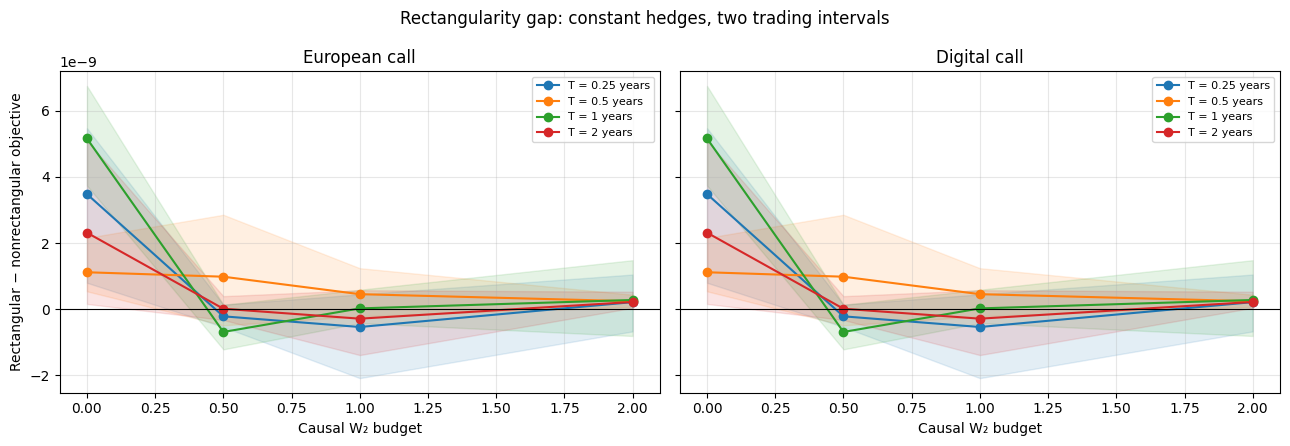

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, payoff_name in zip(axes, payoffs):
    payoff_summary = summary[summary["payoff"] == payoff_name]

    for horizon in horizons:
        data = (
            payoff_summary[payoff_summary["horizon"] == horizon]
            .sort_values("budget")
        )

        line = ax.plot(
            data["budget"],
            data["gap_mean"],
            marker="o",
            label=f"T = {horizon:g} years",
        )[0]

        ax.fill_between(
            data["budget"].to_numpy(),
            data["gap_min"].to_numpy(),
            data["gap_max"].to_numpy(),
            color=line.get_color(),
            alpha=0.12,
        )

    ax.set_title(payoff_name)
    ax.set_xlabel("Causal W₂ budget")
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Rectangular − nonrectangular objective")

fig.suptitle(
    "Rectangularity gap: constant hedges, two trading intervals"
)
fig.tight_layout()

fig.savefig(
    output_dir / "gap_vs_budget.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

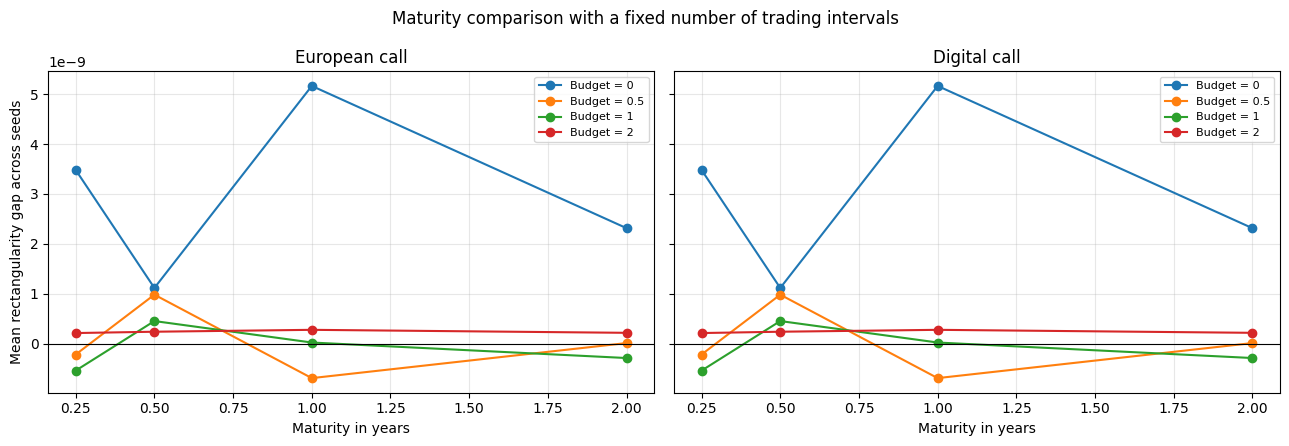

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, payoff_name in zip(axes, payoffs):
    payoff_summary = summary[summary["payoff"] == payoff_name]

    for budget in budgets:
        data = (
            payoff_summary[payoff_summary["budget"] == budget]
            .sort_values("horizon")
        )

        ax.plot(
            data["horizon"],
            data["gap_mean"],
            marker="o",
            label=f"Budget = {budget:g}",
        )

    ax.set_title(payoff_name)
    ax.set_xlabel("Maturity in years")
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Mean rectangularity gap across seeds")

fig.suptitle(
    "Maturity comparison with a fixed number of trading intervals"
)
fig.tight_layout()

fig.savefig(
    output_dir / "gap_vs_horizon.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [115]:
boundary_results = results[
    results["nonrectangular_at_bound"]
    | results["rectangular_at_bound"]
]

display(boundary_results)

,payoff,horizon,budget,seed,n_steps,reference_branches,penalty,nonrectangular_value,rectangular_value,gap,nonrectangular_capital,rectangular_capital,nonrectangular_holding,rectangular_holding,nonrectangular_shortfall,rectangular_shortfall,nonrectangular_at_bound,rectangular_at_bound
0,European call,0.25,0.0,123,2,2,100,-1.850695e-10,5.292089e-09,5.477158e-09,1.100391e-09,5.292089e-09,-2.889990e-10,-2.498586e-09,-1.285461e-11,0.000000e+00,True,True
1,Digital call,0.25,0.0,123,2,2,100,-1.850695e-10,5.292089e-09,5.477158e-09,1.100391e-09,5.292089e-09,-2.889990e-10,-2.498586e-09,-1.285461e-11,0.000000e+00,True,True
2,European call,0.25,0.5,123,2,2,100,4.943003e-09,4.401966e-09,-5.410368e-10,6.394794e-09,3.512406e-09,-4.550172e-10,-4.831419e-10,-1.451791e-11,8.895601e-12,True,True
3,Digital call,0.25,0.5,123,2,2,100,4.943003e-09,4.401966e-09,-5.410368e-10,6.394794e-09,3.512406e-09,-4.550172e-10,-4.831419e-10,-1.451791e-11,8.895601e-12,True,True
4,European call,0.25,1.0,123,2,2,100,3.181474e-09,1.090402e-09,-2.091072e-09,3.631032e-09,9.334006e-10,-9.627070e-10,-3.283864e-10,-4.495573e-12,1.570016e-12,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,Digital call,2.00,0.5,44,2,2,100,2.048767e-10,1.734719e-10,-3.140482e-11,1.600560e-10,9.658905e-11,1.714714e-12,-2.090645e-13,4.482068e-13,7.688284e-13,True,True
92,European call,2.00,1.0,44,2,2,100,1.468408e-09,7.544353e-11,-1.392964e-09,1.737136e-09,3.804203e-11,-7.861793e-11,-9.297980e-13,-2.687279e-12,3.740150e-13,True,True
93,Digital call,2.00,1.0,44,2,2,100,1.468408e-09,7.544353e-11,-1.392964e-09,1.737136e-09,3.804203e-11,-7.861793e-11,-9.297980e-13,-2.687279e-12,3.740150e-13,True,True
94,European call,2.00,2.0,44,2,2,100,-9.020445e-13,5.245774e-10,5.254794e-10,1.183619e-10,6.144520e-10,-3.346909e-12,-4.568569e-11,-1.192640e-12,-8.987465e-13,True,True
